# Mapas geoespaciais de Palmas — Sprint 3

**Projeto Integrador — Inteligência Tributária (Sefin Palmas)**
Entregável E3 (parte geoespacial) | Responsável: Pedro Santos Magalhães Neto

Este notebook produz dois mapas:

1. **Mapa demonstrativo de inadimplência** com os **dados piloto fictícios** do banco (`V2__seed_dados_piloto.sql`). Ele mostra *como* o mapa vai funcionar quando houver dados reais de débitos; os números **não representam Palmas**.
2. **Mapa de indicadores do IBGE** (Censo 2022) por setor censitário urbano do distrito-sede de Palmas, com dados **reais**, que servirá de contexto socioeconômico para cruzar com a inadimplência no futuro.

Saídas: mapas interativos em `docs/mapas/` (HTML) e versões estáticas em `docs/figuras/` (PNG).

## 1. Preparação

In [1]:
from pathlib import Path
import ast, re

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import folium
import branca.colormap as cm
import requests

RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
PASTA_MAPAS = RAIZ / "docs" / "mapas"
PASTA_FIGURAS = RAIZ / "docs" / "figuras"
PASTA_IBGE = RAIZ / "data" / "bruto" / "ibge"
for p in (PASTA_MAPAS, PASTA_FIGURAS, PASTA_IBGE):
    p.mkdir(parents=True, exist_ok=True)

CODIGO_PALMAS = "1721000"
CRS_METRICO = "EPSG:31982"  # SIRGAS 2000 / UTM 22S, adequado para medir distâncias em Palmas

## 2. Malha de setores censitários do IBGE (Censo 2022)

Baixamos o arquivo oficial do IBGE com a malha de setores do Tocantins **já unida** aos agregados de população e domicílios do Censo 2022. O download só acontece na primeira execução; depois, o arquivo fica guardado em `data/bruto/ibge/` (fonte oficial, dado bruto preservado).

> O arquivo tem cerca de 72 MB e **não deve ir para o GitHub**. A pasta `data/bruto/ibge/` está listada no `.gitignore`.

In [2]:
URL_IBGE = ("https://ftp.ibge.gov.br/Censos/Censo_Demografico_2022/Agregados_por_Setores_Censitarios/"
            "malha_com_atributos/setores/gpkg/UF/TO/TO_setores_CD2022.gpkg")
ARQ_IBGE = PASTA_IBGE / "TO_setores_CD2022.gpkg"

if not ARQ_IBGE.exists():
    print("Baixando malha do IBGE (pode levar alguns minutos)...")
    with requests.get(URL_IBGE, stream=True, timeout=120,
                      headers={"User-Agent": "PI-BIINAR-UFT/1.0 (projeto academico)"}) as r:
        r.raise_for_status()
        with open(ARQ_IBGE, "wb") as f:
            for bloco in r.iter_content(chunk_size=1 << 20):
                f.write(bloco)
print("Arquivo:", ARQ_IBGE.relative_to(RAIZ), f"({ARQ_IBGE.stat().st_size/1e6:.0f} MB)")

setores_to = gpd.read_file(ARQ_IBGE)
setores = setores_to[setores_to["CD_MUN"].astype(str) == CODIGO_PALMAS].copy()
print("Setores no Tocantins:", len(setores_to), "| em Palmas:", len(setores))
print("Colunas:", list(setores.columns))

Arquivo: data/bruto/ibge/TO_setores_CD2022.gpkg (76 MB)
Setores no Tocantins: 4119 | em Palmas: 734
Colunas: ['CD_SETOR', 'SITUACAO', 'CD_SIT', 'CD_TIPO', 'AREA_KM2', 'CD_REGIAO', 'NM_REGIAO', 'CD_UF', 'NM_UF', 'CD_MUN', 'NM_MUN', 'CD_DIST', 'NM_DIST', 'CD_SUBDIST', 'NM_SUBDIST', 'CD_BAIRRO', 'NM_BAIRRO', 'CD_NU', 'NM_NU', 'CD_FCU', 'NM_FCU', 'CD_AGLOM', 'NM_AGLOM', 'CD_RGINT', 'NM_RGINT', 'CD_RGI', 'NM_RGI', 'CD_CONCURB', 'NM_CONCURB', 'v0001', 'v0002', 'v0003', 'v0004', 'v0005', 'v0006', 'v0007', 'geometry']


### 2.1 Variáveis usadas

Segundo o dicionário de dados do IBGE, `v0001` é o **total de pessoas** residentes no setor e `AREA_KM2` é a área do setor. Com elas calculamos a **densidade demográfica** (pessoas por km²). A célula abaixo mostra a descrição oficial das variáveis `v0001` a `v0007`, lida do dicionário publicado pelo IBGE, para conferência.

In [3]:
URL_DIC = ("https://ftp.ibge.gov.br/Censos/Censo_Demografico_2022/Agregados_por_Setores_Censitarios/"
           "malha_com_atributos/Dicionario_de_dados_malha_agregados.xlsx")
ARQ_DIC = PASTA_IBGE / "Dicionario_de_dados_malha_agregados.xlsx"
try:
    if not ARQ_DIC.exists():
        ARQ_DIC.write_bytes(requests.get(URL_DIC, timeout=60).content)
    dic = pd.read_excel(ARQ_DIC, header=None).astype(str)
    linhas_v = dic[dic.apply(lambda l: l.str.contains(r"^v000[1-7]$", case=False).any(), axis=1)]
    display(linhas_v)
except Exception as erro:
    print("Não foi possível ler o dicionário (não impede o mapa):", erro)

,0,1,2
50,V0001,nan,Total de pessoas
51,V0002,nan,Total de Domicílios (DPPO + DPPV + DPPUO + DPI...
52,V0003,nan,Total de Domicílios Particulares (DPPO + DPPV ...
53,V0004,nan,Total de Domicílios Coletivos (DCCM + DCSM)
54,V0005,nan,Média de moradores em Domicílios Particulares ...
55,V0006,nan,Percentual de Domicílios Particulares Ocupados...
56,V0007,nan,Total de Domicílios Particulares Ocupados (DPP...


In [4]:
# O IBGE publica as variáveis como texto; "X" indica valor omitido por sigilo.
for col in [c for c in setores.columns if re.fullmatch(r"v000\d", c)]:
    setores[col] = pd.to_numeric(setores[col], errors="coerce")

urbanos = setores[setores["SITUACAO"].astype(str).str.lower().str.startswith("urb")].copy()

# Palmas tem setores urbanos em distritos distantes (como Taquaruçu e Buritirana).
# Ficamos com o distrito-sede, identificado como o distrito com mais moradores urbanos.
dist_sede = urbanos.groupby("CD_DIST")["v0001"].sum().idxmax()
nome_sede = urbanos.loc[urbanos["CD_DIST"] == dist_sede, "NM_DIST"].iloc[0] if "NM_DIST" in urbanos else dist_sede
print("Distritos com setores urbanos:", urbanos["CD_DIST"].nunique(), "| distrito-sede:", nome_sede)
urbanos = urbanos[urbanos["CD_DIST"] == dist_sede].copy()
urbanos["densidade"] = urbanos["v0001"] / urbanos["AREA_KM2"]
urbanos = urbanos.to_crs("EPSG:4326")

print("Setores urbanos do distrito-sede:", len(urbanos))
print(f"População nesses setores: {urbanos['v0001'].sum():,.0f}".replace(",", "."))
print("Setores sem dado de população (sigilo ou vazios):", urbanos["v0001"].isna().sum())
urbanos["densidade"].describe().round(0)

Distritos com setores urbanos: 3 | distrito-sede: Palmas
Setores urbanos do distrito-sede: 694
População nesses setores: 291.175
Setores sem dado de população (sigilo ou vazios): 0


count      694.0
mean      4139.0
std       4420.0
min          0.0
25%       1064.0
50%       3369.0
75%       5634.0
max      43031.0
Name: densidade, dtype: float64

## 3. Mapa 1 — Inadimplência por setor urbano (DADOS FICTÍCIOS)

### 3.1 Lendo os dados piloto

Os dados piloto estão no arquivo SQL da Sprint 2. Lemos só as tabelas `imovel` e `debito_tributario` e **descartamos CPF/CNPJ** logo na leitura (LGPD: não precisamos de dado pessoal para um mapa por região).

In [5]:
ARQ_SEED = RAIZ / "src" / "database" / "schema" / "V2__seed_dados_piloto.sql"
sql = ARQ_SEED.read_text(encoding="utf-8")

def ler_insert(tabela):
    """Extrai as linhas do INSERT INTO tributario.<tabela> como DataFrame."""
    bloco = re.search(rf"INSERT INTO tributario\.{tabela}\s*\((.*?)\)\s*VALUES(.*?)ON CONFLICT",
                      sql, flags=re.S)
    colunas = [c.strip() for c in bloco.group(1).split(",")]
    linhas = []
    for linha in bloco.group(2).splitlines():
        linha = linha.split("--")[0].strip().rstrip(",")
        if linha.startswith("("):
            linhas.append(ast.literal_eval(linha.replace("NULL", "None")))
    return pd.DataFrame(linhas, columns=colunas)

imoveis = ler_insert("imovel").drop(columns=["cpf_cnpj_proprietario", "logradouro"])
debitos = ler_insert("debito_tributario").drop(columns=["cpf_cnpj"])

iptu = debitos.merge(imoveis, on="inscricao_imobiliaria", how="inner")
print("Débitos piloto:", len(debitos), "| débitos de IPTU ligados a um imóvel:", len(iptu))
iptu[["id_debito", "setor_urbano", "tipo_tributo", "valor_debito", "status_pagamento"]]

Débitos piloto: 10 | débitos de IPTU ligados a um imóvel: 7


,id_debito,setor_urbano,tipo_tributo,valor_debito,status_pagamento
0,deb-001,SU-01,IPTU,850.0,PAGO
1,deb-002,SU-02,IPTU,1200.0,VENCIDO
2,deb-003,SU-01,IPTU,600.0,PENDENTE
3,deb-004,SU-03,IPTU,120.0,PAGO
4,deb-005,SU-02,IPTU,3500.0,PARCELADO
5,deb-006,SU-02,IPTU,8700.0,VENCIDO
6,deb-007,SU-04,IPTU,22000.0,VENCIDO


In [6]:
iptu["vencido"] = iptu["status_pagamento"].eq("VENCIDO")
por_setor = (iptu.groupby("setor_urbano")
             .agg(debitos=("id_debito", "count"),
                  vencidos=("vencido", "sum"),
                  valor_total=("valor_debito", "sum"),
                  valor_vencido=("valor_debito", lambda s: s[iptu.loc[s.index, "vencido"]].sum()))
             .reset_index())
por_setor["taxa_inadimplencia"] = por_setor["vencidos"] / por_setor["debitos"]
por_setor

,setor_urbano,debitos,vencidos,valor_total,valor_vencido,taxa_inadimplencia
0,SU-01,2,0,1450.0,0.0,0.000000
1,SU-02,3,2,13400.0,9900.0,0.666667
2,SU-03,1,0,120.0,0.0,0.000000
3,SU-04,1,1,22000.0,22000.0,1.000000


### 3.2 Onde ficam os setores SU-01 a SU-04?

Os dados piloto **não têm localização real**: os bairros ("Centro", "Jardim América"...) são genéricos e não existem com esses nomes em Palmas. Para demonstrar o mapa, dividimos a área urbana do distrito-sede em **quatro faixas arbitrárias de norte a sul** (cada uma com um quarto dos setores) e associamos cada faixa a um setor piloto: SU-01 a mais ao norte, SU-04 a mais ao sul.

> **Essa associação é inventada, apenas para fins de demonstração.** O mapa não diz nada sobre a inadimplência real dessas regiões.

In [7]:
metrico = urbanos.to_crs(CRS_METRICO)
centros_y = metrico.geometry.centroid.y
# qcut divide em 4 grupos com o mesmo número de setores; 0 = faixa mais ao sul, 3 = mais ao norte
faixa = pd.qcut(centros_y.rank(method="first"), 4, labels=False)
metrico["zona"] = faixa.map({3: "SU-01", 2: "SU-02", 1: "SU-03", 0: "SU-04"})

zonas = metrico.dissolve(by="zona").reset_index()[["zona", "geometry"]].to_crs("EPSG:4326")
zonas = zonas.merge(por_setor, left_on="zona", right_on="setor_urbano", how="left")
zonas[["zona", "debitos", "vencidos", "taxa_inadimplencia", "valor_vencido"]]

,zona,debitos,vencidos,taxa_inadimplencia,valor_vencido
0,SU-01,2,0,0.000000,0.0
1,SU-02,3,2,0.666667,9900.0
2,SU-03,1,0,0.000000,0.0
3,SU-04,1,1,1.000000,22000.0


In [8]:
AVISO = ("<div style='position:fixed;top:10px;left:50%;transform:translateX(-50%);z-index:9999;"
         "background:#b30000;color:white;padding:8px 16px;font:bold 14px sans-serif;border-radius:6px'>"
         "DADOS FICTÍCIOS — demonstração do método, não representa Palmas</div>")

escala1 = cm.LinearColormap(["#fee5d9", "#fb6a4a", "#a50f15"], vmin=0, vmax=1,
                            caption="Taxa de inadimplência (débitos vencidos ÷ total) — FICTÍCIO")
minx, miny, maxx, maxy = urbanos.total_bounds
centro = [(miny + maxy) / 2, (minx + maxx) / 2]  # centro do retângulo que envolve a área urbana
m1 = folium.Map(location=centro, zoom_start=12, tiles="OpenStreetMap")
folium.GeoJson(
    zonas.assign(taxa_txt=zonas["taxa_inadimplencia"].map("{:.0%}".format),
                 valor_txt=zonas["valor_vencido"].map(lambda v: f"R$ {v:,.2f}")),
    style_function=lambda f: {"fillColor": escala1(f["properties"]["taxa_inadimplencia"]),
                              "color": "#333", "weight": 1.5, "fillOpacity": 0.7},
    tooltip=folium.GeoJsonTooltip(["zona", "debitos", "vencidos", "taxa_txt", "valor_txt"],
                                  aliases=["Setor piloto", "Débitos", "Vencidos",
                                           "Inadimplência", "Valor vencido"]),
).add_to(m1)
escala1.add_to(m1)
m1.get_root().html.add_child(folium.Element(AVISO))
m1.save(PASTA_MAPAS / "mapa1_inadimplencia_piloto_FICTICIO.html")
m1

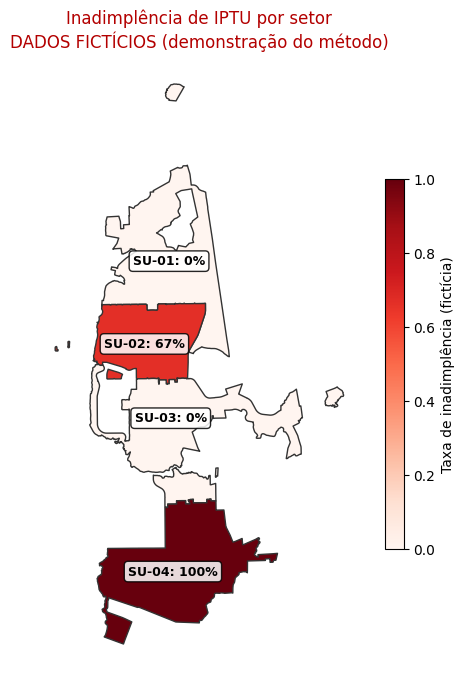

In [9]:
fig, ax = plt.subplots(figsize=(7, 8))
zonas.plot(column="taxa_inadimplencia", cmap="Reds", vmin=0, vmax=1, edgecolor="#333",
           legend=True, legend_kwds={"label": "Taxa de inadimplência (fictícia)", "shrink": 0.6}, ax=ax)
for _, z in zonas.iterrows():
    p = z.geometry.representative_point()
    ax.annotate(f"{z['zona']}: {z['taxa_inadimplencia']:.0%}", (p.x, p.y), ha="center", va="center",
                fontsize=9, weight="bold", bbox=dict(boxstyle="round", fc="white", alpha=0.85))
ax.set_title("Inadimplência de IPTU por setor\nDADOS FICTÍCIOS (demonstração do método)", color="#b30000")
ax.set_axis_off()
fig.savefig(PASTA_FIGURAS / "m1_inadimplencia_piloto_FICTICIO.png", bbox_inches="tight", dpi=110)
plt.show()

O mapa demonstra o método: cada setor urbano recebe a proporção dos seus débitos de IPTU que estão vencidos, e a cor mais escura indica maior inadimplência. Com os dados piloto (fictícios e com apenas 7 débitos de IPTU), as taxas variam de 0% a 100% e **não permitem nenhuma conclusão** sobre Palmas; quando a base real de débitos estiver disponível, basta trocar a fonte de dados e usar o setor urbano real de cada imóvel.

## 4. Mapa 2 — Densidade demográfica por setor censitário urbano (IBGE, dados reais)

In [10]:
dados = urbanos.dropna(subset=["densidade"]).copy()
limite = dados["densidade"].quantile(0.95)  # evita que poucos setores muito densos "apaguem" o resto
escala2 = cm.LinearColormap(["#f7fbff", "#6baed6", "#08306b"], vmin=0, vmax=limite,
                            caption="Pessoas por km² (Censo 2022) — escala cortada no percentil 95")
nomes_tt = {"CD_SETOR": "Setor", "NM_BAIRRO": "Bairro", "v0001": "Pessoas", "dens_txt": "Densidade"}
colunas_tt = [c for c in nomes_tt
              if c == "dens_txt" or (c in dados.columns and dados[c].notna().any())]
m2 = folium.Map(location=centro, zoom_start=12, tiles="OpenStreetMap")
folium.GeoJson(
    dados.assign(dens_txt=dados["densidade"].map(lambda d: f"{d:,.0f} hab/km²".replace(",", ".")))
         [colunas_tt + ["densidade", "geometry"]],
    style_function=lambda f: {"fillColor": escala2(min(f["properties"]["densidade"], limite)),
                              "color": "#555", "weight": 0.3, "fillOpacity": 0.75},
    tooltip=folium.GeoJsonTooltip(colunas_tt, aliases=[nomes_tt[c] for c in colunas_tt]),
).add_to(m2)
escala2.add_to(m2)
m2.save(PASTA_MAPAS / "mapa2_densidade_ibge_2022.html")
m2

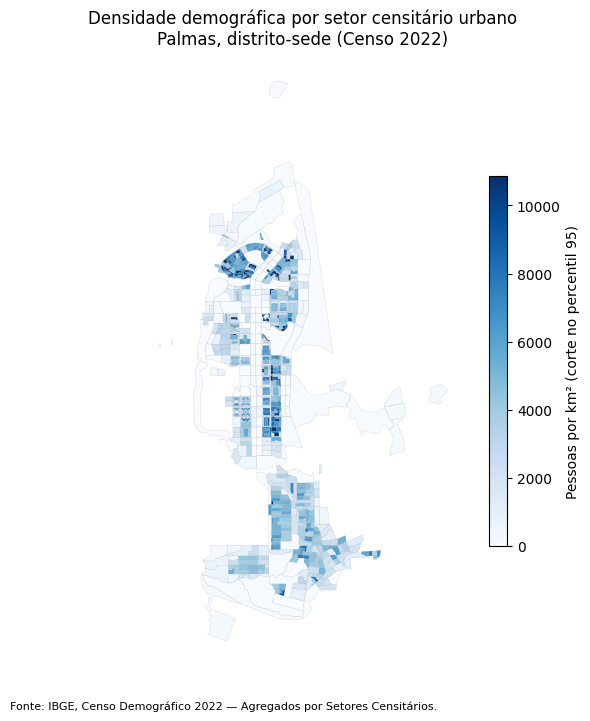

,CD_SETOR,v0001,AREA_KM2,densidade
3782,172100005000700,569,0.013,43031.437
3695,172100005000595,620,0.016,38342.345
3504,172100005000395,410,0.012,32827.567
3811,172100005000732,627,0.023,27426.250
3505,172100005000396,400,0.015,26171.810


In [11]:
fig, ax = plt.subplots(figsize=(7, 8))
dados.plot(column="densidade", cmap="Blues", vmin=0, vmax=limite, linewidth=0.1, edgecolor="#999",
           legend=True, legend_kwds={"label": "Pessoas por km² (corte no percentil 95)", "shrink": 0.6}, ax=ax)
ax.set_title("Densidade demográfica por setor censitário urbano\nPalmas, distrito-sede (Censo 2022)")
ax.set_axis_off()
fig.text(0.1, 0.06, "Fonte: IBGE, Censo Demográfico 2022 — Agregados por Setores Censitários.", fontsize=8)
fig.savefig(PASTA_FIGURAS / "m2_densidade_ibge_2022.png", bbox_inches="tight", dpi=110)
plt.show()

top = dados.nlargest(5, "densidade")
cols = [c for c in ["CD_SETOR", "NM_BAIRRO", "v0001", "AREA_KM2", "densidade"]
        if c in top.columns and top[c].notna().any()]
top[cols].round(3)

## 5. Limitações

1. O Mapa 1 usa **dados fictícios** e uma **associação arbitrária** entre setores piloto e regiões: serve apenas para validar o método.
2. O Mapa 2 é real, mas mostra **densidade demográfica**, não inadimplência. Para cruzar os dois, a base de débitos precisa ter a localização real de cada imóvel (setor censitário, bairro ou coordenadas).
3. Setores com dados omitidos por sigilo pelo IBGE ficam sem cor no Mapa 2.